In [1]:
import os, json, warnings
warnings.filterwarnings('ignore')

import numpy as np
import rasterio
from rasterio.windows import Window
import cv2
from skimage.morphology import skeletonize, remove_small_objects
from skimage.measure import label, regionprops
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap

DATA_DIR = r'D:\Github\Canal Pipeline\TLBC_DSM_DTM'
OUT_DIR  = os.path.join(DATA_DIR, 'outputs', '03_extraction_v3')
os.makedirs(OUT_DIR, exist_ok=True)

FILES = {
    'ATTANUR_1': 'TLBC_D95_ATTANUR_1_ortho.tif',
    'ATTANUR_2': 'TLBC_D95_ATTANUR_2_ortho.tif',
    'ATTANUR_3': 'TLBC_D95_ATTANUR_3_ortho.tif',
    'ATTANUR_4': 'TLBC_D95_ATTANUR_4_ortho.tif',
    'SHAKAPUR':  'TLBC_D95_SHAKAPUR_ortho.tif',
}
PX_SIZE = {
    'ATTANUR_1': 0.0462, 'ATTANUR_2': 0.0462, 'ATTANUR_3': 0.0462,
    'ATTANUR_4': 0.0352, 'SHAKAPUR':  0.0342,
}

PATCH_SIZE   = 1024   # full-res pixels per patch  (~47 m at 4.6 cm/px)
N_PATCHES    = 12     # patches sampled per tile
OVERVIEW_PX  = 1200   # overview scale for smart sampling

VCMAP = LinearSegmentedColormap.from_list(
    'v', ['#8B4513','#d2b48c','#f5f5f5','#90ee90','#006400'])

print('Setup complete')

Setup complete


In [2]:
# ── Core helpers ──────────────────────────────────────────────────────────────

def vari(r, g, b):
    d = g.astype(float) + r.astype(float) - b.astype(float)
    d = np.where(np.abs(d) < 1e-6, 1e-6, d)
    return np.clip((g.astype(float) - r.astype(float)) / d, -1, 1)

def stretch(rgb, lo=2, hi=98):
    out = np.zeros_like(rgb, dtype=np.uint8)
    for c in range(3):
        ch = rgb[:,:,c].astype(float)
        v  = ch[ch > 0]
        if v.size == 0: continue
        pl, ph = np.percentile(v, [lo, hi])
        if ph > pl:
            out[:,:,c] = np.clip((ch-pl)/(ph-pl)*255, 0, 255).astype(np.uint8)
    return out

def read_patch(src, col_off, row_off, size=PATCH_SIZE):
    w = min(size, src.width  - col_off)
    h = min(size, src.height - row_off)
    data = src.read([1,2,3,4], window=Window(col_off, row_off, w, h)).astype(np.float32)
    return data[0], data[1], data[2], data[3]

# ── Fix 1: Linearity filter ───────────────────────────────────────────────────
def linearity_filter(mask, min_aspect=3.0, max_blob_area=None):
    """
    Keep only elongated connected components (canals are long + thin).
    Drops large irregular blobs = bare soil / field surfaces.
    min_aspect : major_axis / minor_axis threshold
    max_blob_area : also keep anything smaller than this (small canal segments)
    """
    labeled  = label(mask, connectivity=2)
    filtered = np.zeros_like(mask, dtype=bool)
    for region in regionprops(labeled):
        if region.area < 8:
            continue
        minor = region.minor_axis_length
        if minor < 1e-3:
            aspect = region.major_axis_length
        else:
            aspect = region.major_axis_length / minor
        # keep if elongated OR small enough (isolated canal pixel cluster)
        if aspect >= min_aspect or (max_blob_area and region.area <= max_blob_area):
            filtered[labeled == region.label] = True
    return filtered

# ── Fix 2: Smart patch sampling ───────────────────────────────────────────────
def smart_patch_positions(fpath, n_patches=N_PATCHES, patch_size=PATCH_SIZE,
                          overview_px=OVERVIEW_PX):
    """
    Read a mid-scale overview, score candidate patch windows by canal-line
    density (low-VARI + linear morphology), return top-N full-res (col,row) offsets.
    """
    with rasterio.open(fpath) as src:
        W, H  = src.width, src.height
        scale = max(1, max(W, H) // overview_px)
        ow, oh = W // scale, H // scale
        data  = src.read([1,2,3,4], out_shape=(4, oh, ow)).astype(np.float32)

    r, g, b, a = data[0], data[1], data[2], data[3]
    valid  = a > 128
    bright = (r + g + b) / 3.0
    vi     = vari(r, g, b)
    grey   = np.abs(r-g) + np.abs(g-b)

    # Canal hint at overview scale: low-VARI features (both concrete + earthen)
    canal_hint = (valid & (vi < 0.07) & (bright > 80)).astype(np.uint8)

    # Emphasise LINEAR features using morphological opening with thin kernels
    # (horizontal + vertical + diagonal)
    linear = np.zeros_like(canal_hint)
    for angle in [0, 90, 45, 135]:
        length = max(3, 15 // scale * scale // scale)   # ~15 overview px
        k = cv2.getRotationMatrix2D((length//2, 0), angle, 1)
        kern = np.zeros((3, length), np.uint8); kern[1,:] = 1
        kern = cv2.warpAffine(kern, k, (length, 3)).astype(np.uint8)
        if kern.sum() > 0:
            opened = cv2.morphologyEx(canal_hint, cv2.MORPH_OPEN, kern)
            linear = np.maximum(linear, opened)

    # Score each candidate window (step = half patch in overview coords)
    pw = max(4, patch_size // scale)
    step = max(2, pw // 2)
    scores = []
    for ry in range(0, oh - pw + 1, step):
        for cx in range(0, ow - pw + 1, step):
            vw = valid[ry:ry+pw, cx:cx+pw]
            if vw.sum() < pw*pw*0.35:
                continue
            lw = linear[ry:ry+pw, cx:cx+pw]
            score = lw.sum() / vw.sum()
            co = min(cx * scale, W - patch_size)
            ro = min(ry * scale, H - patch_size)
            scores.append((score, co, ro))

    scores.sort(reverse=True)

    # Pick top unique positions (no overlap within half-patch distance)
    half = patch_size // 2
    chosen, used = [], []
    for score, co, ro in scores:
        if all(abs(co-uc) > half or abs(ro-ur) > half for uc,ur in used):
            chosen.append((co, ro))
            used.append((co, ro))
        if len(chosen) >= n_patches:
            break

    print(f'  Smart sampling: scale 1:{scale}  overview {ow}x{oh}  '
          f'→ {len(chosen)} patch positions found')
    return chosen, W, H, scale

# ── Canal extraction (full-res patch) ────────────────────────────────────────
def extract_canals(r, g, b, alpha, px_m=0.0462):
    valid  = alpha > 128
    bright = (r + g + b) / 3.0
    grey   = np.abs(r-g) + np.abs(g-b)
    vi     = vari(r, g, b)

    fic_min_px  = max(2,  int(0.15 / px_m))
    fic_max_px  = int(1.8 / px_m)
    conc_min_px = max(3,  int(0.6 / px_m))
    connect_px  = max(5,  int(2.5 / px_m))

    k3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
    k5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))

    # --- concrete ---
    c_raw = (valid & (vi < 0.06) & (bright > 120) & (grey < 25)).astype(np.uint8)
    c_raw = cv2.morphologyEx(c_raw, cv2.MORPH_OPEN,  k3)
    c_raw = cv2.morphologyEx(c_raw, cv2.MORPH_CLOSE, k5)
    # FIX 1a: linearity filter on concrete — drop large soil blobs
    concrete = linearity_filter(c_raw.astype(bool), min_aspect=2.5,
                                max_blob_area=int((3.0/px_m)**2))

    # --- earthen candidates ---
    e_raw = (valid & (vi < 0.09) & (bright > 65) & (bright < 215)
             & (r > b + 3) & (grey >= 10) & ~concrete).astype(np.uint8)
    e_raw = cv2.morphologyEx(e_raw, cv2.MORPH_OPEN,  k3)
    e_raw = cv2.morphologyEx(e_raw, cv2.MORPH_CLOSE, k3)
    # FIX 1b: linearity filter on earthen
    earthen = linearity_filter(e_raw.astype(bool), min_aspect=2.5,
                               max_blob_area=int((2.0/px_m)**2))

    # --- widths ---
    c_dist = cv2.distanceTransform(concrete.astype(np.uint8)*255, cv2.DIST_L2, 5) * 2
    e_dist = cv2.distanceTransform(earthen.astype(np.uint8)*255,  cv2.DIST_L2, 5) * 2
    c_skel = skeletonize(concrete)
    e_skel = skeletonize(earthen)

    # --- FIC vs bund via connectivity ---
    ck        = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,
                                          (connect_px*2+1, connect_px*2+1))
    c_dilated = cv2.dilate(concrete.astype(np.uint8), ck).astype(bool)
    e_labels  = label(earthen, connectivity=2)
    fic_mask  = np.zeros_like(earthen)
    bund_mask = np.zeros_like(earthen)

    for region in regionprops(e_labels):
        comp      = e_labels == region.label
        skel_comp = comp & e_skel
        if skel_comp.sum() == 0:
            bund_mask |= comp; continue
        med_w   = float(np.median(e_dist[skel_comp]))
        touches = bool((comp & c_dilated).any())
        if touches and (fic_min_px <= med_w <= fic_max_px):
            fic_mask  |= comp
        else:
            bund_mask |= comp

    # --- blockage candidates ---
    veg_in_concrete  = concrete & (vi > 0.08)
    dark_in_concrete = concrete & (bright < 100)
    veg_in_fic       = fic_mask.astype(bool) & (vi > 0.10)

    return dict(
        concrete=concrete, fic=fic_mask.astype(bool), bund=bund_mask.astype(bool),
        c_skel=c_skel, e_skel=e_skel, c_width=c_dist, e_width=e_dist,
        veg_block=veg_in_concrete.astype(bool),
        sediment_block=dark_in_concrete.astype(bool),
        fic_veg_block=veg_in_fic, px_m=px_m,
    )

print('Helpers ready')

Helpers ready


In [3]:
# ── Visualisation helper ──────────────────────────────────────────────────────
def show_patch(r, g, b, alpha, masks, title=''):
    px_m = masks['px_m']
    rgb  = stretch(np.stack([r,g,b], axis=2).astype(np.uint8))
    vi_p = vari(r, g, b); vi_p[alpha<=128] = np.nan

    fig, axes = plt.subplots(1, 5, figsize=(26, 6))
    fig.suptitle(title, fontsize=10)

    axes[0].imshow(rgb); axes[0].set_title('RGB'); axes[0].axis('off')

    axes[1].imshow(vi_p, cmap=VCMAP, vmin=-0.3, vmax=0.5)
    axes[1].set_title('VARI'); axes[1].axis('off')

    ov = rgb.copy()
    ov[masks['concrete']] = [180,180,180]
    ov[masks['fic']]      = [210,130, 40]
    ov[masks['bund']]     = [140, 70, 20]
    axes[2].imshow(ov)
    axes[2].set_title('Classes  Grey=concrete  Orange=FIC  Brown=bund')
    axes[2].legend(handles=[
        Patch(facecolor='#b4b4b4', label='Concrete'),
        Patch(facecolor='#d28228', label='FIC'),
        Patch(facecolor='#8c4614', label='Field bund'),
    ], loc='lower right', fontsize=7)
    axes[2].axis('off')

    sk = rgb.copy()
    sk[masks['c_skel']]                = [255,255,  0]
    sk[masks['e_skel'] & masks['fic']] = [255,140,  0]
    cskel_px = masks['c_skel'] & (masks['c_width'] > 0)
    fskel_px = masks['e_skel'] & masks['fic'] & (masks['e_width'] > 0)
    wc = float(np.median(masks['c_width'][cskel_px])) if cskel_px.any() else 0
    wf = float(np.median(masks['e_width'][fskel_px])) if fskel_px.any() else 0
    axes[3].imshow(sk)
    axes[3].set_title(f'Skeleton  Yellow=concrete  Orange=FIC\n'
                      f'Concrete {wc:.1f}px={wc*px_m:.2f}m  '
                      f'FIC {wf:.1f}px={wf*px_m:.2f}m')
    axes[3].axis('off')

    bl = rgb.copy()
    bl[masks['veg_block']]      = [  0,220,  0]
    bl[masks['sediment_block']] = [220,  0,  0]
    bl[masks['fic_veg_block']]  = [255,200,  0]
    axes[4].imshow(bl)
    axes[4].set_title('Blockage candidates\n'
                      'Green=veg  Red=sediment  Yellow=veg-in-FIC')
    axes[4].axis('off')

    plt.tight_layout()
    plt.show()

print('Viz helper ready')

Viz helper ready


## Step 1 — Develop on ATTANUR_1 with smart sampling

Smart sampling ATTANUR_1 ...
  Smart sampling: scale 1:43  overview 754x1209  → 6 patch positions found
  Patch 1 col=27907 row=0: concrete=0.4%  FIC=0.0%  bund=0.0%


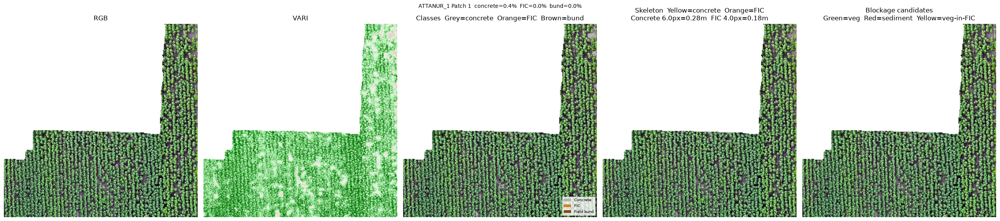

  Patch 2 col=31218 row=0: concrete=1.3%  FIC=0.0%  bund=0.0%


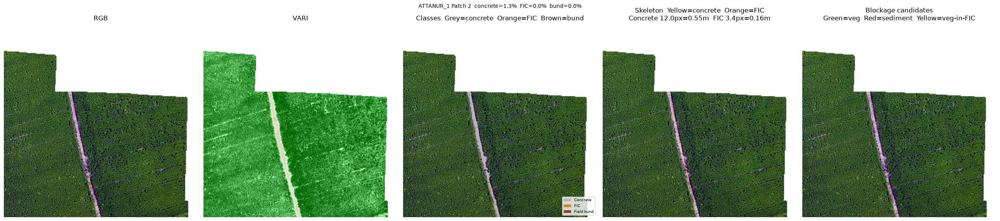

  Patch 3 col=30272 row=0: concrete=4.9%  FIC=1.9%  bund=0.1%


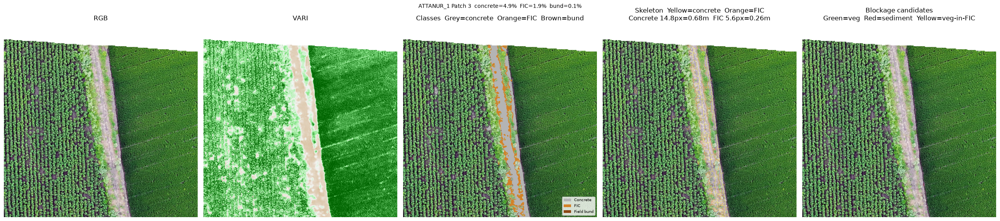

  Patch 4 col=29326 row=0: concrete=0.0%  FIC=0.0%  bund=0.0%


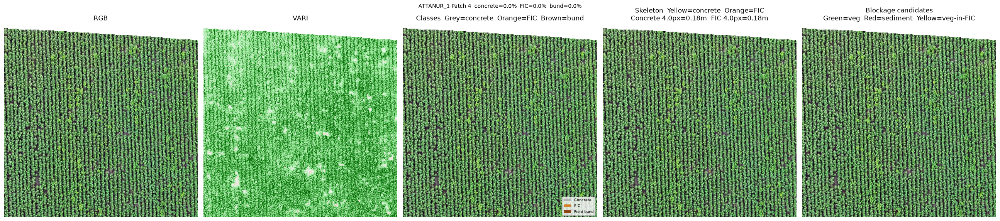

  Patch 5 col=14190 row=32637: concrete=0.9%  FIC=48.4%  bund=1.1%


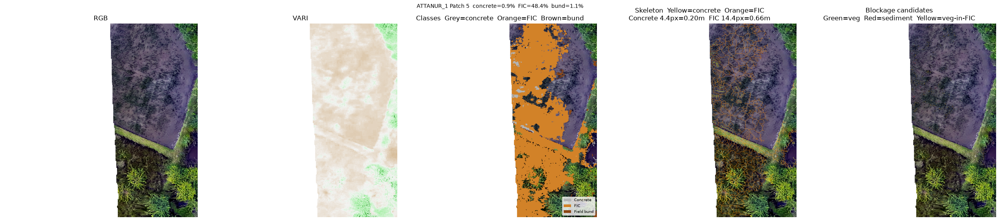

  Patch 6 col=1892 row=25542: concrete=0.7%  FIC=4.4%  bund=20.1%


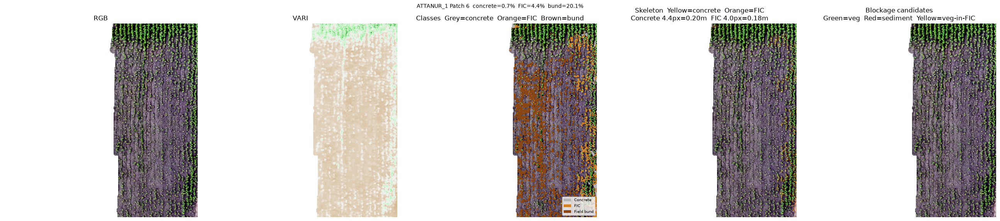

In [4]:
TAG   = 'ATTANUR_1'
fpath = os.path.join(DATA_DIR, FILES[TAG])
px_m  = PX_SIZE[TAG]

print(f'Smart sampling {TAG} ...')
positions, W, H, sc = smart_patch_positions(fpath, n_patches=6)

with rasterio.open(fpath) as src:
    for i, (co, ro) in enumerate(positions):
        r, g, b, a = read_patch(src, co, ro)
        if (a > 128).sum() < PATCH_SIZE*PATCH_SIZE*0.3:
            continue
        masks = extract_canals(r, g, b, a, px_m=px_m)
        vp  = (a > 128).sum()
        cp  = masks['concrete'].sum() / vp * 100
        fp  = masks['fic'].sum()      / vp * 100
        bp  = masks['bund'].sum()     / vp * 100
        print(f'  Patch {i+1} col={co} row={ro}: '
              f'concrete={cp:.1f}%  FIC={fp:.1f}%  bund={bp:.1f}%')
        show_patch(r, g, b, a, masks,
                   title=f'{TAG} Patch {i+1}  concrete={cp:.1f}%  FIC={fp:.1f}%  bund={bp:.1f}%')

## Step 2 — Grid sweep all 5 tiles


  ATTANUR_1
  Smart sampling: scale 1:43  overview 754x1209  → 12 patch positions found
  Patches: 12  |  Concrete: 6.37%  FIC: 8.62%  Bund: 2.98%
  Concrete width: 0.6 m  |  FIC width: 0.35 m
  Veg blockage: 0.01%  |  Sediment blockage: 0.13%


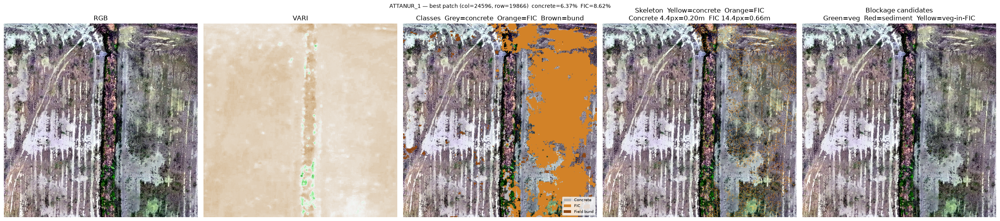


  ATTANUR_2
  Smart sampling: scale 1:114  overview 699x1206  → 12 patch positions found
  Patches: 12  |  Concrete: 9.02%  FIC: 3.71%  Bund: 0.65%
  Concrete width: 0.39 m  |  FIC width: 0.33 m
  Veg blockage: 0.0%  |  Sediment blockage: 0.07%


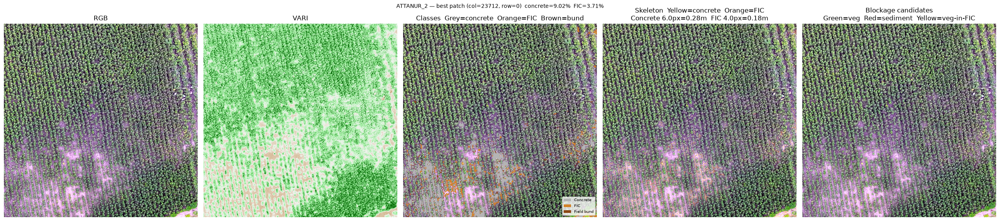


  ATTANUR_3
  Smart sampling: scale 1:115  overview 547x1209  → 12 patch positions found
  Patches: 11  |  Concrete: 11.34%  FIC: 10.52%  Bund: 2.08%
  Concrete width: 0.41 m  |  FIC width: 0.32 m
  Veg blockage: 0.01%  |  Sediment blockage: 0.11%


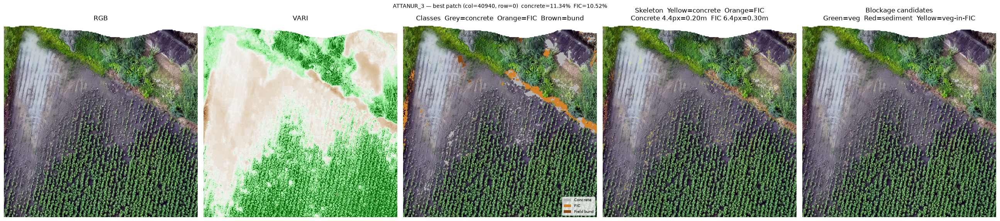


  ATTANUR_4
  Smart sampling: scale 1:36  overview 491x1215  → 12 patch positions found
  Patches: 11  |  Concrete: 5.8%  FIC: 11.12%  Bund: 1.31%
  Concrete width: 0.37 m  |  FIC width: 0.32 m
  Veg blockage: 0.0%  |  Sediment blockage: 0.01%


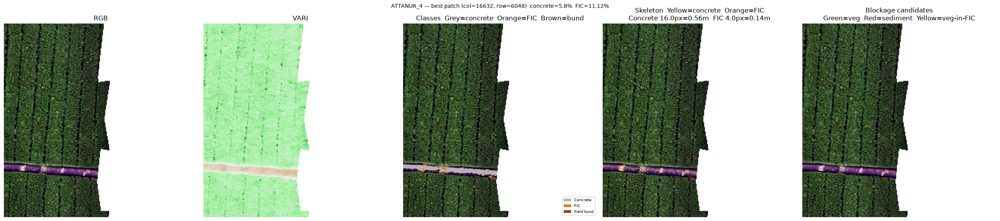


  SHAKAPUR
  Smart sampling: scale 1:73  overview 1212x573  → 12 patch positions found
  Patches: 12  |  Concrete: 2.51%  FIC: 13.98%  Bund: 5.85%
  Concrete width: 0.21 m  |  FIC width: 0.23 m
  Veg blockage: 0.0%  |  Sediment blockage: 0.01%


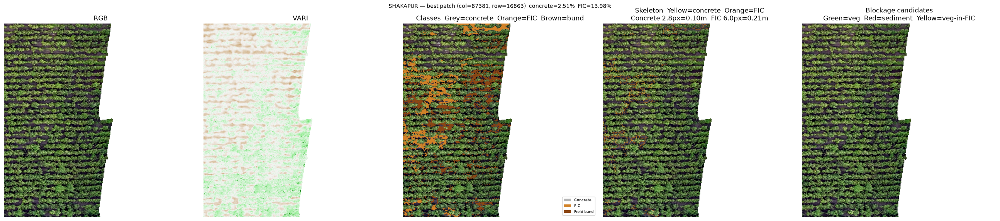


Stats saved.


In [5]:
all_stats = {}

for TAG, fname in FILES.items():
    fpath = os.path.join(DATA_DIR, fname)
    px_m  = PX_SIZE[TAG]
    print(f'\n{"="*55}\n  {TAG}\n{"="*55}')

    positions, W, H, sc = smart_patch_positions(fpath, n_patches=N_PATCHES)

    acc = dict(concrete=[], fic=[], bund=[], veg_blk=[], sed_blk=[],
               cw=[], fw=[])
    best_patch, best_vp = None, 0

    with rasterio.open(fpath) as src:
        for co, ro in positions:
            r, g, b, a = read_patch(src, co, ro)
            vp = int((a > 128).sum())
            if vp < PATCH_SIZE*PATCH_SIZE*0.35:
                continue

            masks = extract_canals(r, g, b, a, px_m=px_m)

            acc['concrete'].append(masks['concrete'].sum()/vp*100)
            acc['fic'].append(masks['fic'].sum()/vp*100)
            acc['bund'].append(masks['bund'].sum()/vp*100)
            acc['veg_blk'].append(masks['veg_block'].sum()/vp*100)
            acc['sed_blk'].append(masks['sediment_block'].sum()/vp*100)

            cskel = masks['c_skel'] & (masks['c_width']>0)
            fskel = masks['e_skel'] & masks['fic'] & (masks['e_width']>0)
            if cskel.any(): acc['cw'].append(float(np.median(masks['c_width'][cskel]))*px_m)
            if fskel.any(): acc['fw'].append(float(np.median(masks['e_width'][fskel]))*px_m)

            if vp > best_vp:
                best_vp = vp
                best_patch = (r.copy(),g.copy(),b.copy(),a.copy(),
                              {k:v.copy() if hasattr(v,'copy') else v
                               for k,v in masks.items()}, co, ro)

    def avg(lst): return round(float(np.mean(lst)),2) if lst else 0
    s = {
        'patches':           len(acc['concrete']),
        'concrete_pct':      avg(acc['concrete']),
        'fic_pct':           avg(acc['fic']),
        'bund_pct':          avg(acc['bund']),
        'veg_blockage_pct':  avg(acc['veg_blk']),
        'sediment_block_pct':avg(acc['sed_blk']),
        'concrete_width_m':  avg(acc['cw']),
        'fic_width_m':       avg(acc['fw']),
    }
    all_stats[TAG] = s

    print(f'  Patches: {s["patches"]}  |  '
          f'Concrete: {s["concrete_pct"]}%  FIC: {s["fic_pct"]}%  Bund: {s["bund_pct"]}%')
    print(f'  Concrete width: {s["concrete_width_m"]} m  |  '
          f'FIC width: {s["fic_width_m"]} m')
    print(f'  Veg blockage: {s["veg_blockage_pct"]}%  |  '
          f'Sediment blockage: {s["sediment_block_pct"]}%')

    if best_patch:
        r,g,b,a,m,co,ro = best_patch
        show_patch(r,g,b,a,m,
                   title=f'{TAG} — best patch (col={co}, row={ro})  '
                         f'concrete={s["concrete_pct"]}%  FIC={s["fic_pct"]}%')

with open(os.path.join(OUT_DIR,'grid_stats_all.json'),'w') as f:
    json.dump(all_stats, f, indent=2)
print('\nStats saved.')

## Step 3 — Summary table

In [6]:
print(f'{"Tile":<12} {"Patches":>8} {"Concrete%":>10} {"FIC%":>7} '
      f'{"Bund%":>7} {"C-w(m)":>8} {"FIC-w(m)":>9} {"VegBlk%":>8} {"SedBlk%":>8}')
print('-'*83)
for tag, s in all_stats.items():
    print(f'{tag:<12} {s["patches"]:>8} {s["concrete_pct"]:>10} '
          f'{s["fic_pct"]:>7} {s["bund_pct"]:>7} '
          f'{s["concrete_width_m"]:>8} {s["fic_width_m"]:>9} '
          f'{s["veg_blockage_pct"]:>8} {s["sediment_block_pct"]:>8}')

Tile          Patches  Concrete%    FIC%   Bund%   C-w(m)  FIC-w(m)  VegBlk%  SedBlk%
-----------------------------------------------------------------------------------
ATTANUR_1          12       6.37    8.62    2.98      0.6      0.35     0.01     0.13
ATTANUR_2          12       9.02    3.71    0.65     0.39      0.33      0.0     0.07
ATTANUR_3          11      11.34   10.52    2.08     0.41      0.32     0.01     0.11
ATTANUR_4          11        5.8   11.12    1.31     0.37      0.32      0.0     0.01
SHAKAPUR           12       2.51   13.98    5.85     0.21      0.23      0.0     0.01


## Step 4 — Combined 5-tile summary figure (saved to disk)

  Smart sampling: scale 1:43  overview 754x1209  → 1 patch positions found
  Smart sampling: scale 1:114  overview 699x1206  → 1 patch positions found
  Smart sampling: scale 1:115  overview 547x1209  → 1 patch positions found
  Smart sampling: scale 1:36  overview 491x1215  → 1 patch positions found
  Smart sampling: scale 1:73  overview 1212x573  → 1 patch positions found


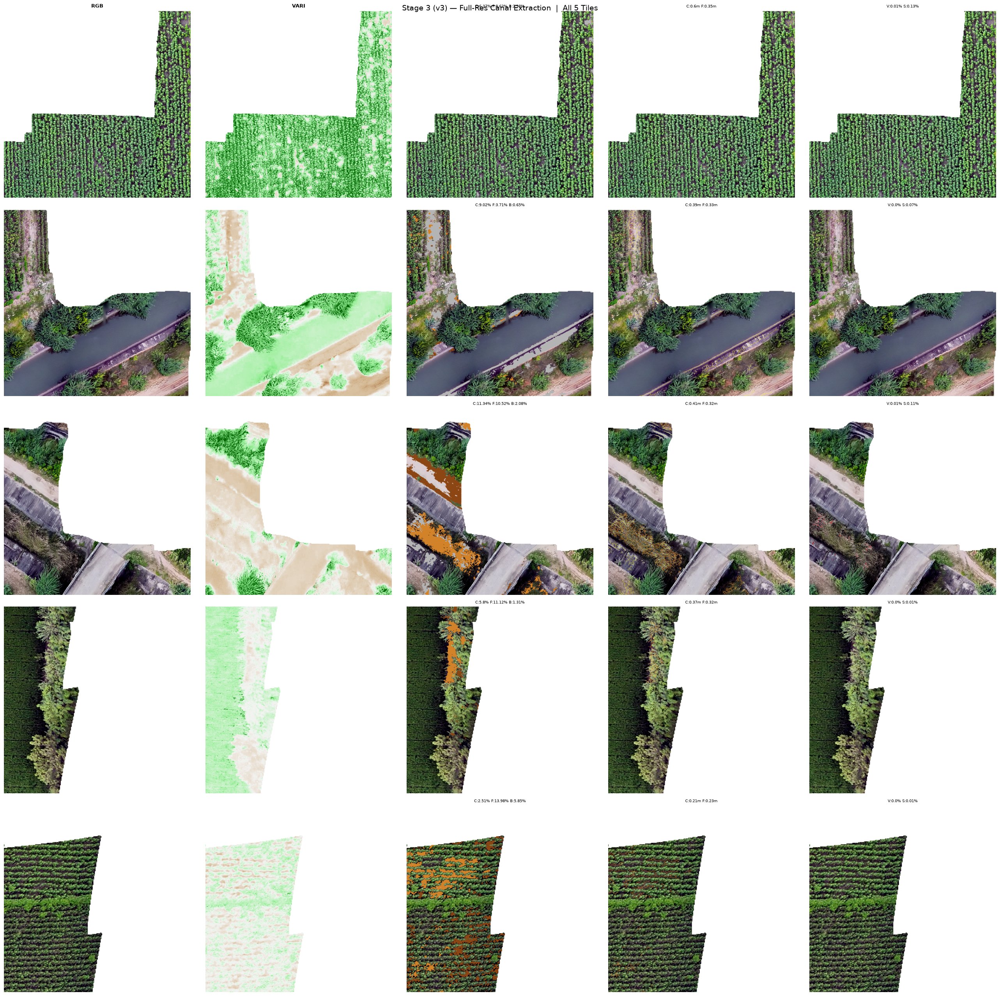

Saved -> D:\Github\Canal Pipeline\TLBC_DSM_DTM\outputs\03_extraction_v3\ALL_TILES_v3_extraction.png


In [9]:
fig, axes = plt.subplots(5, 5, figsize=(26, 26))
fig.suptitle('Stage 3 (v3) — Full-Res Canal Extraction  |  All 5 Tiles', fontsize=14)
for ci, ct in enumerate(['RGB','VARI','Canal classes','Skeleton','Blockage']):
    axes[0,ci].set_title(ct, fontsize=9, fontweight='bold')

for row_i, (TAG, fname) in enumerate(FILES.items()):
    fpath = os.path.join(DATA_DIR, fname)
    px_m  = PX_SIZE[TAG]
    s     = all_stats[TAG]

    # use first smart-sampled position for figure
    positions, W, H, sc = smart_patch_positions(fpath, n_patches=1)
    co, ro = positions[0]
    with rasterio.open(fpath) as src:
        r, g, b, a = read_patch(src, co, ro)

    masks = extract_canals(r, g, b, a, px_m=px_m)
    rgb_s = stretch(np.stack([r,g,b],axis=2).astype(np.uint8))
    vi_p  = vari(r,g,b); vi_p[a<=128] = np.nan

    axes[row_i,0].imshow(rgb_s); axes[row_i,0].axis('off')
    axes[row_i,0].set_ylabel(TAG, fontsize=9, fontweight='bold')

    axes[row_i,1].imshow(vi_p, cmap=VCMAP, vmin=-0.3, vmax=0.5)
    axes[row_i,1].axis('off')

    ov = rgb_s.copy()
    ov[masks['concrete']] = [180,180,180]
    ov[masks['fic']]      = [210,130, 40]
    ov[masks['bund']]     = [140, 70, 20]
    axes[row_i,2].imshow(ov)
    axes[row_i,2].set_title(f"C:{s['concrete_pct']}% F:{s['fic_pct']}% B:{s['bund_pct']}%",
                             fontsize=7)
    axes[row_i,2].axis('off')

    sk = rgb_s.copy()
    sk[masks['c_skel']]                = [255,255,  0]
    sk[masks['e_skel'] & masks['fic']] = [255,140,  0]
    axes[row_i,3].imshow(sk)
    axes[row_i,3].set_title(f"C:{s['concrete_width_m']}m F:{s['fic_width_m']}m",
                             fontsize=7)
    axes[row_i,3].axis('off')

    bl = rgb_s.copy()
    bl[masks['veg_block']]      = [  0,220,  0]
    bl[masks['sediment_block']] = [220,  0,  0]
    bl[masks['fic_veg_block']]  = [255,200,  0]
    axes[row_i,4].imshow(bl)
    axes[row_i,4].set_title(f"V:{s['veg_blockage_pct']}% S:{s['sediment_block_pct']}%",
                             fontsize=7)
    axes[row_i,4].axis('off')

plt.tight_layout()
out = os.path.join(OUT_DIR, 'ALL_TILES_v3_extraction.png')
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved -> {out}')